# 05 · Model Training Analysis

**Artemis-X - AI perception for lunar rock and obstacle detection**

**Objective.** Document the single authorised YOLO11n training run (E.1c) and analyse its convergence and hardware behaviour from the saved logs. **This notebook never starts training.**

**Research questions**

1. Which architecture and settings were used, and why?
2. Did training converge, and did it overfit?
3. Was the run technically sound?

**Inputs (published, pixel-free artifacts)**

- `artifacts/training/results.csv`
- `artifacts/training/e1c_args.yaml`
- `artifacts/training/e1c_summary.json`
- `artifacts/training/checkpoint_inventory.json`

> **Provisional results.** All labels were produced by an automated pipeline (S2-H policy) and have **not** been verified by humans. Metrics are measured on synthetic renders only and do not establish performance on real lunar imagery or readiness for rover deployment.

## Setup
The notebook imports the `artemis_x` package from `src/` and reads only published artifacts. It never trains a model, rebuilds a dataset or evaluates the held-out test split.

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "artemis_x").is_dir())
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from artemis_x.config import paths
from artemis_x.reporting import artifacts as A, plots as P
P.use_style()
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 90)
# Dataset pixels are never committed (redistribution licence unconfirmed). Set ARTEMIS_SHOW_LOCAL_IMAGES=1 to view
# local images when the dataset folder is present.
SHOW_LOCAL_IMAGES = os.environ.get("ARTEMIS_SHOW_LOCAL_IMAGES") == "1" and paths.local_dataset_available()
FIG = paths.ARTIFACTS / "figures"
print("artemis_x ready | local dataset present:", paths.local_dataset_available(), "| showing local images:", SHOW_LOCAL_IMAGES)

artemis_x ready | local dataset present: True | showing local images: False


## 1. Model and settings
**YOLO11n** (Ultralytics 8.4.174) is a single-stage, anchor-free detector with about 2.6 M parameters. It was fine-tuned from the
official COCO-pretrained `yolo11n.pt` (sha256 `0ebbc80d…`). It was chosen for its latency budget: a rover-side detector must run in
real time on modest hardware.

Training was launched once, through the guarded wrapper `backend/training/train.py`. That wrapper:
- requires an explicit authorisation flag and environment variable;
- verifies the effective arguments before the first batch;
- blocks Ultralytics' automatic OOM batch-halving, NaN epoch replay and time-based epoch changes;
- records telemetry every second.

Historical command, shown for reference and **not executed here**:
```
ARTEMIS_TRAINING_AUTHORIZED=1 uv run --no-sync python -m training.train --arm A_steps --seed 42 --authorized --fresh --data-view \
    --run-dir ../experiments/task-e/full-training-config-a-200-s42 --set epochs=200 save_period=10 imgsz=736 batch=16 workers=4 ...
```

In [2]:
import yaml
args = yaml.safe_load((paths.ARTIFACTS / "training/e1c_args.yaml").read_text(encoding="utf-8"))
keys = ["model", "pretrained", "epochs", "imgsz", "batch", "workers", "optimizer", "lr0", "lrf", "momentum", "weight_decay", "cos_lr",
        "warmup_epochs", "amp", "seed", "deterministic", "single_cls", "close_mosaic", "mosaic", "fliplr", "flipud", "hsv_h", "hsv_s", "hsv_v",
        "patience", "save_period", "cache"]
pd.DataFrame({"value": [str(args.get(k)) for k in keys]}, index=keys)   # str: no display rounding

,value
model,yolo11n.pt
pretrained,True
epochs,200
imgsz,736
batch,16
workers,4
optimizer,SGD
lr0,0.01
lrf,0.01
momentum,0.937


In [3]:
s = A.training_summary(); t = s["telemetry"]
pd.Series({"status": s["status"], "epochs": s["epochs_recorded"], "wall-clock (h)": s["wall_clock_h_epochs"],
           "epoch duration median (s)": s["epoch_duration_s"]["median"], "training throughput median (img/s)": s["img_per_s_epoch"]["median"],
           "GPU util, training windows, median (%)": t["gpu_util_train_window"]["median"], "peak VRAM (MiB)": t["vram_mib"]["max"],
           "max GPU temperature (C)": t["temp_c"]["max"], "thermal-throttle samples": t["thermal_slowdown_samples"],
           "min available RAM (GB)": t["ram_available_gb"]["min"],
           "hardware": "NVIDIA RTX 5060 Laptop GPU (8 GB), AMP fp16"}).to_frame("E.1c run")

,E.1c run
status,COMPLETED
epochs,200
wall-clock (h),1.14
epoch duration median (s),19.8
training throughput median (img/s),125.4
"GPU util, training windows, median (%)",87.0
peak VRAM (MiB),5537.0
max GPU temperature (C),71.0
thermal-throttle samples,0
min available RAM (GB),5.3


## 2. Losses

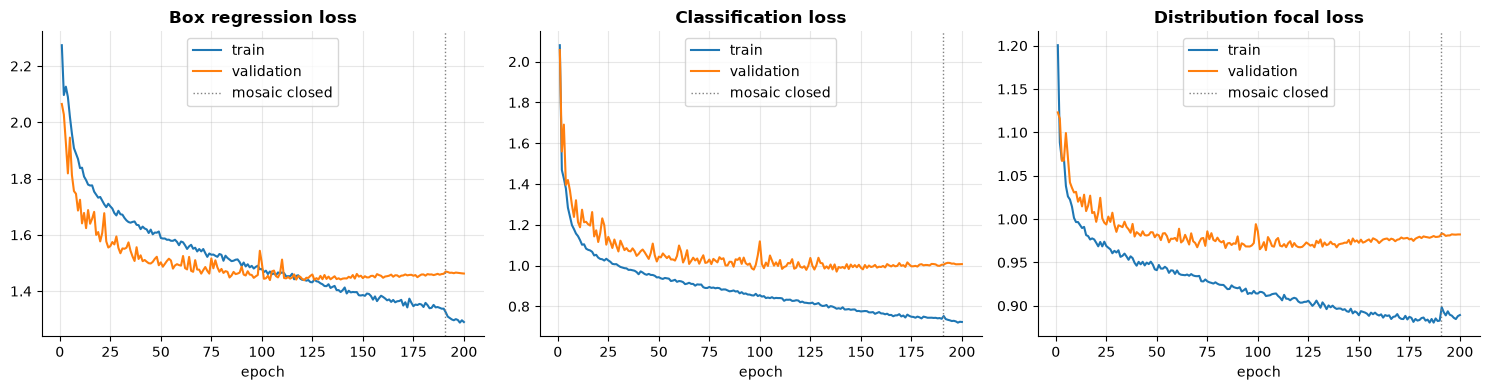

In [4]:
h = A.training_history()
P.training_losses(h)

Training losses decrease throughout. Validation losses reach their minimum between epochs 104 and 138 and then drift
slightly upward. That is **mild overfitting**, possibly to label noise. The step at epoch 191 is the planned switch-off of mosaic
augmentation for the last 10 epochs.

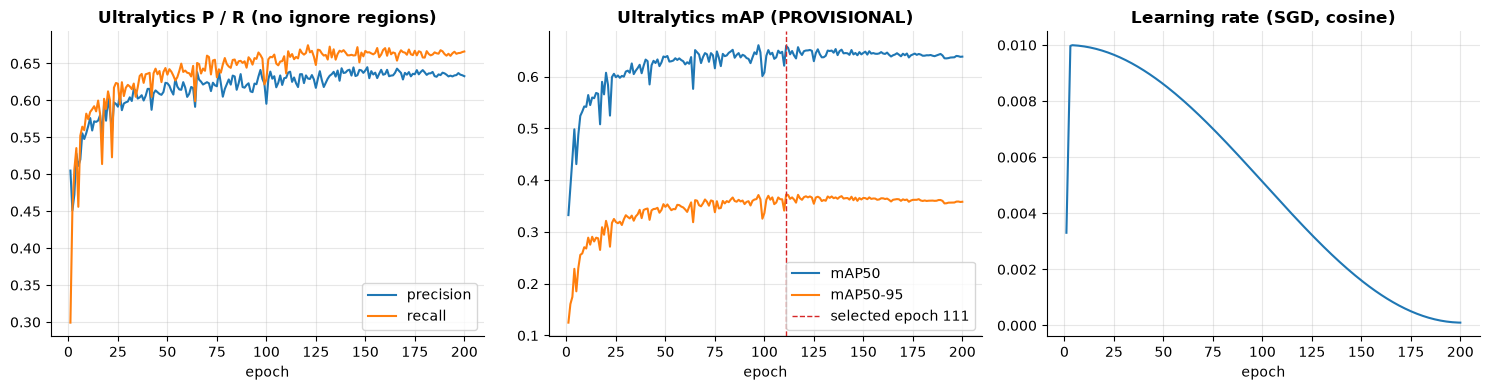

In [5]:
P.validation_metrics(h)

Ultralytics' built-in validation counts detections on REVIEW regions as false positives, so its mAP is **provisional** and
was not used for model selection (see notebook 06).

In [6]:
m = pd.DataFrame(s["milestones"]).T
m[["box", "cls", "vbox", "vcls", "P", "R", "m50", "m5095", "lr_pg0"]].rename(columns={"vbox": "val box", "vcls": "val cls", "m50": "mAP50", "m5095": "mAP50-95"})

,box,cls,val box,val cls,P,R,mAP50,mAP50-95,lr_pg0
50,1.589,0.943,1.502,1.044,0.623,0.635,0.638,0.348,0.009
100,1.479,0.855,1.499,1.119,0.595,0.628,0.608,0.336,0.005
150,1.386,0.775,1.446,0.99,0.64,0.667,0.646,0.366,0.002
200,1.29,0.723,1.462,1.007,0.633,0.666,0.639,0.358,0.0


## 3. Hardware behaviour

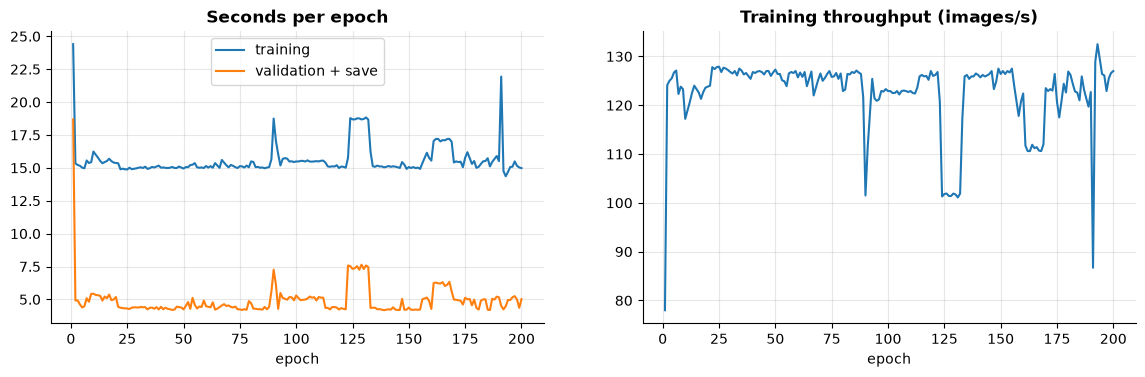

In [7]:
e = A.epoch_performance()
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(e["epoch"], e["train_s"], label="training"); ax[0].plot(e["epoch"], e["val_save_s"], label="validation + save"); ax[0].set_title("Seconds per epoch"); ax[0].legend()
ax[1].plot(e["epoch"], e["img_per_s_epoch"]); ax[1].set_title("Training throughput (images/s)")
for a in ax: a.set_xlabel("epoch")
plt.show()

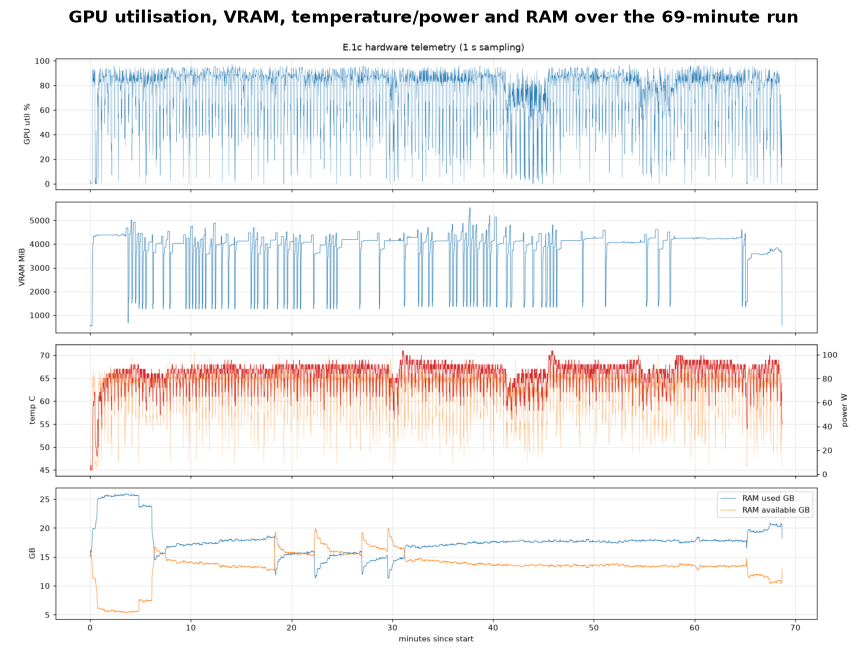

In [8]:
P.show_png(FIG / "e_hardware_telemetry.png", "GPU utilisation, VRAM, temperature/power and RAM over the 69-minute run")

Two short slow phases (epochs 124-132 and 161-169) coincided with **lower** GPU power and temperature but **higher**
CPU use. They are attributed to host-side slowdown; that is a hypothesis, because CPU clocks were not logged. There was no OOM, NaN,
repeated epoch or thermal throttling.

## 4. Checkpoints
42 checkpoints were verified (loadable, finite, class `rock`). `epochN.pt` follows Ultralytics' 0-based naming (N+1 completed epochs); the `epoch_completed_*` copies are aligned to completed epochs.

In [9]:
inv = A.checkpoint_inventory()
inv[inv["file"].isin(["best.pt", "last.pt", "epoch_completed_050.pt", "epoch_completed_100.pt", "epoch_completed_120.pt", "epoch_completed_200.pt", "epoch10.pt"])]

,file,completed_epochs,MB,names_ok,finite,resumable,sha256
2,epoch10.pt,11.0,10.25,True,True,True,d03a84c2055c...
9,epoch_completed_050.pt,50.0,10.26,True,True,True,12a3bdef8271...
19,epoch_completed_100.pt,100.0,10.26,True,True,True,1763c48242b7...
23,epoch_completed_120.pt,120.0,10.26,True,True,True,36955f0de304...
39,epoch_completed_200.pt,200.0,10.27,True,True,True,52167b452797...
40,best.pt,NaN,5.23,True,True,False,413d0481a728...
41,last.pt,NaN,5.23,True,True,False,f24a35ef7c97...


## Provenance
Each artifact below is a verified copy (or path-sanitised derivative) of a historical experiment output; `scripts/verify_artifacts.py` re-checks every hash.

In [10]:
A.provenance(['training/results.csv', 'training/e1c_summary.json', 'training/e1c_args.yaml', 'figures/e_hardware_telemetry.png'])

,artifact,mode,source (local experiments/),sha256
0,artifacts/training/results.csv,COPY,experiments/task-e/full-training-config-a-200-s42/results.csv,25c030b08c79d59a...
1,artifacts/training/e1c_summary.json,COPY,experiments/task-e/full-training-config-a-200-s42/analysis/summary.json,01f8e3e3e43c9a50...
2,artifacts/training/e1c_args.yaml,SANITISED,experiments/task-e/full-training-config-a-200-s42/args.yaml,d41cffc35e52aa3e...
3,artifacts/figures/e_hardware_telemetry.png,COPY,experiments/task-e/full-training-config-a-200-s42/analysis/hardware_telemetry.png,a2b5bdc22441ff5e...


## Conclusion
- One 200-epoch run of YOLO11n on Config A (seed 42) completed in 68.7 minutes. It was technically clean: no OOM, NaN or
  throttling, and every checkpoint was verified.
- The model **converged by about epoch 100-120**, with mild overfitting afterwards. Training longer is not justified by these data.
- Ultralytics' own validation metrics are provisional. Checkpoint choice uses the ignore-aware evaluation in the next notebook.

**Next:** [06_model_selection.ipynb](06_model_selection.ipynb)